# Task 1: DINOv3 vs CLIP image retrieval (SeaDronesSee) · v2

**Changes in v2**: DINOv3 is no longer loaded from Hugging Face. It now uses **Meta's official weights + `torch.hub`** (the weight URL comes from Meta's approval email; the file is downloaded once to Google Drive).
Before the email arrives, you can turn on the **DINOv2 fallback** (open weights, no request needed) to run the whole pipeline. Once the email arrives, turn both on to also get a DINOv2 vs DINOv3 comparison.

**Goal**: compare DINOv3 and CLIP on image retrieval using **frozen pretrained features** (no training).

- **DINOv3 / DINOv2**: self-supervised (no text); features lean towards **visual / geometric structure** (shape, texture, local structure).
- **CLIP**: trained with image–text contrastive learning; features lean towards **semantics + text alignment**.

**Experimental design** (detection dataset → retrieval task):
1. Crop every object using the COCO bboxes (swimmer, boat, jetski, …).
2. **Query = val crops, Gallery = train crops**; same class = "relevant" (class-based retrieval).
3. Metrics: **mAP** (incl. per-class AP and macro-mAP), **Recall@K**, **Precision@K**.
4. Extra experiments: CLIP text→image retrieval (DINO cannot do this), robustness under perturbations such as rotation/blur, t-SNE visualisation, CIFAR-10 sanity check (optional).

**No data is stored on your own computer**: the dataset is downloaded with `kagglehub` to Colab's temporary cloud disk and is wiped when the runtime disconnects; the DINOv3 weights (~0.3 GB) are stored in your Google Drive.

| Step | Approx. time (Colab T4, rough estimate) | Disk |
|---|---|---|
| Download DINOv3 ViT-B/16 weights to Drive (first time only) | 1–3 min | ~0.3 GB on Drive |
| Download + unzip SeaDronesSee (~10 GB zip) | 10–25 min (almost instant if Colab has a cached Kaggle mount) | Peak ~20 GB (zip deleted after extraction) |
| Crop objects (default: up to 400+100 per class) | 2–6 min | a few hundred MB RAM |
| Feature extraction per model | < 2 min | — |

> Times are estimates; actual times depend on the Colab machine and network speed.

## 0. Before running

**You only need to fill in two things** (both in the config cell in Section 1):
- `DINOV3_WEIGHTS_URL`: copy the URL on the **ViT-B/16 distilled (LVD-1689M)** line of Meta's email and paste it in. If the email has not arrived yet, leave it empty and keep `USE_DINOV2 = True`.
- `USE_DINOV3` / `USE_DINOV2`: choose which DINO models to run.

Other preparation:
1. **Runtime → Change runtime type → GPU (T4 is enough)**.
2. **Kaggle API token**: [Kaggle Settings](https://www.kaggle.com/settings) → API → *Create New Token*. In Colab's left sidebar 🔑 **Secrets**, add `KAGGLE_API_TOKEN` (or `KAGGLE_USERNAME` + `KAGGLE_KEY` from an old-style `kaggle.json`) and enable *Notebook access*. You can also upload `kaggle.json` at runtime.
3. **No Hugging Face token needed any more**: CLIP is a public model, and DINOv3 comes from Meta's official download.
4. Section 2 will ask for **Google Drive authorisation**; just accept (weights are saved to `MyDrive/dinov3_weights/`).

> ⚠️ The URL in Meta's email usually **expires**. After that, wget returns a 403 error; weights already in Drive are not affected. Do not share this URL or commit it to a public repository.

In [1]:
# Install dependencies. DINOv3's torch.hub entry point (hubconf.py) imports these packages; Colab lacks some of them by default
!pip -q install -U kagglehub torchmetrics termcolor omegaconf ftfy regex

import os, glob, json, random, time, zipfile, math, subprocess
from collections import Counter, defaultdict
import numpy as np
import torch
import torchvision
from torchvision.transforms import v2
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter
import transformers

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch:", torch.__version__, "| torchvision:", torchvision.__version__, "| transformers:", transformers.__version__, "| device:", device)
if device == "cpu":
    print("⚠️ No GPU detected: go to Runtime → Change runtime type and choose GPU, otherwise feature extraction will be slow.")

torch: 2.14.1+cu130 | torchvision: 0.29.1+cu130 | transformers: 5.22.1 | device: cuda


## 1. Config ✏️ (the cell you need to fill in)

- `DINOV3_WEIGHTS_URL`: paste the ViT-B/16 distilled (LVD-1689M) URL from Meta's email (keep the quotes).
- `USE_DINOV3`: set to `True` when the weights are available. If the URL is empty and there is no weight file in Drive, DINOv3 is skipped automatically.
- `USE_DINOV2`: fallback / extra comparison. DINOv2 uses `dinov2_vitb14_reg` (ViT-B/14 + registers, open weights).
- **For a quick first run**: lower `MAX_PER_CLASS_GALLERY` and `MAX_PER_CLASS_QUERY` (e.g. 100 / 30).
- `PAD_RATIO`: keep some extra context around the bbox when cropping. SeaDronesSee objects (especially swimmers) are very small, so the bbox alone contains too little information.
- `MIN_BOX_SIDE`: very small boxes (e.g. < 16 px) are basically noise after upscaling to 224, so they are dropped.
- All default models are ViT-B size (~86M parameters), which keeps the comparison fair.

In [2]:
CFG = dict(
    # ---------- DINOv3 (Meta official weights) ----------
    USE_DINOV3 = True,
    DINOV3_WEIGHTS_URL = "",     # ✏️ paste the "ViT-B/16 distilled (LVD-1689M)" URL from the email, e.g. "https://dinov3.llamameta.net/....pth?Policy=..." (removed here before sharing; weights are already in Drive)
    DINOV3_ARCH = "dinov3_vitb16",                               # torch.hub entrypoint (must match the weights)
    DINOV3_DRIVE_DIR = "/content/drive/MyDrive/dinov3_weights",
    DINOV3_FILENAME = "dinov3_vitb16_pretrain_lvd1689m.pth",
    # ---------- DINOv2 (open-weights fallback) ----------
    USE_DINOV2 = True,
    DINOV2_ARCH = "dinov2_vitb14_reg",
    # ---------- CLIP (HF, public, no token needed) ----------
    CLIP_ID = "openai/clip-vit-base-patch16",                    # larger counterpart: openai/clip-vit-large-patch14
    # ---------- data / crop ----------
    MAX_PER_CLASS_GALLERY = 400,   # max train crops per class used as gallery
    MAX_PER_CLASS_QUERY   = 100,   # max val crops per class used as queries
    MIN_BOX_SIDE = 16,             # drop bboxes whose short side (px) is below this
    PAD_RATIO    = 0.5,            # enlarge the box by (1+PAD_RATIO) when cropping, to keep surrounding context
    DINO_IMG_SIZE = 224,           # DINO input size; must be a multiple of 16 for DINOv3 and 14 for DINOv2 (224 works for both)
    BATCH_SIZE   = 64,
    SEED         = 0,
    RUN_SANITY_CIFAR = False,      # run the CIFAR-10 sanity check? (extra ~170 MB download)
)
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"])
{k: (v[:40] + "...") if k == "DINOV3_WEIGHTS_URL" and v else v for k, v in CFG.items()}

{'USE_DINOV3': True,
 'DINOV3_WEIGHTS_URL': 'https://dinov3.llamameta.net/dinov3_vitb...',
 'DINOV3_ARCH': 'dinov3_vitb16',
 'DINOV3_DRIVE_DIR': '/content/drive/MyDrive/dinov3_weights',
 'DINOV3_FILENAME': 'dinov3_vitb16_pretrain_lvd1689m.pth',
 'USE_DINOV2': True,
 'DINOV2_ARCH': 'dinov2_vitb14_reg',
 'CLIP_ID': 'openai/clip-vit-base-patch16',
 'MAX_PER_CLASS_GALLERY': 400,
 'MAX_PER_CLASS_QUERY': 100,
 'MIN_BOX_SIDE': 16,
 'PAD_RATIO': 0.5,
 'DINO_IMG_SIZE': 224,
 'BATCH_SIZE': 64,
 'SEED': 0,
 'RUN_SANITY_CIFAR': False}

## 2. Mount Google Drive and download the DINOv3 weights (only once)

- Meta's README says to **download with `wget`, not with a browser**.
- If the file is already in Drive, the **download is skipped**. A new Colab runtime does not need to download it again.
- After downloading, check the file size (ViT-B/16 is about 330 MB). If it is only a few KB, the URL has usually expired or was copied incompletely, and an error page was downloaded instead.

In [3]:
try:
    from google.colab import drive, userdata
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DINOV3_WEIGHTS_PATH = None
if CFG["USE_DINOV3"]:
    if IN_COLAB:
        drive.mount("/content/drive")
    os.makedirs(CFG["DINOV3_DRIVE_DIR"], exist_ok=True)
    wpath = os.path.join(CFG["DINOV3_DRIVE_DIR"], CFG["DINOV3_FILENAME"])

    if os.path.exists(wpath) and os.path.getsize(wpath) > 100e6:
        print(f"✅ Weights already present, skipping download: {wpath} ({os.path.getsize(wpath)/1e6:.0f} MB)")
    elif CFG["DINOV3_WEIGHTS_URL"].strip():
        print("Downloading DINOv3 weights with wget ...")
        tmp = wpath + ".part"
        r = subprocess.run(["wget", "-q", "--show-progress", "-O", tmp, CFG["DINOV3_WEIGHTS_URL"].strip()])
        size = os.path.getsize(tmp) if os.path.exists(tmp) else 0
        if r.returncode == 0 and size > 100e6:
            os.replace(tmp, wpath)
            print(f"✅ Download complete: {wpath} ({size/1e6:.0f} MB)")
        else:
            if os.path.exists(tmp): os.remove(tmp)
            print(f"❌ Download failed (wget exit code {r.returncode}, size {size/1e6:.2f} MB). Check that the URL is complete and not expired.")
    else:
        print("ℹ️ DINOV3_WEIGHTS_URL is empty and there are no weights in Drive.")

    if os.path.exists(wpath) and os.path.getsize(wpath) > 100e6:
        DINOV3_WEIGHTS_PATH = wpath
    else:
        print("→ Skipping DINOv3 this run." + (" Using the DINOv2 fallback." if CFG["USE_DINOV2"] else " ⚠️ DINOv2 is also off; only CLIP will run."))

Mounted at /content/drive
✅ Weights already present, skipping download: /content/drive/MyDrive/dinov3_weights/dinov3_vitb16_pretrain_lvd1689m.pth (343 MB)


## 3. Kaggle authentication

- `kagglehub` **automatically reads** `KAGGLE_API_TOKEN` or `KAGGLE_USERNAME`/`KAGGLE_KEY` from Colab Secrets.
- If no Secrets are set, this cell asks you to upload `kaggle.json` (stored only in Colab's temporary environment).

In [4]:
def get_secret(name):
    if IN_COLAB:
        try:
            return userdata.get(name)
        except Exception:
            return None
    return os.environ.get(name)

has_kaggle = any(get_secret(k) for k in ["KAGGLE_API_TOKEN", "KAGGLE_KEY"]) or os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json"))
if has_kaggle:
    print("✅ Kaggle credentials found")
elif IN_COLAB:
    print("No Kaggle secret found, please upload kaggle.json:")
    from google.colab import files
    up = files.upload()
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    with open(os.path.expanduser("~/.kaggle/kaggle.json"), "wb") as f:
        f.write(up["kaggle.json"])
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    print("✅ kaggle.json placed in ~/.kaggle/")

✅ Kaggle credentials found


## 4. Download SeaDronesSee (Object Detection v2, compressed)

`kagglehub.dataset_download` will:
- if Colab has a cache of this dataset → mount it directly at `/kaggle/input/...` (fast);
- otherwise download the zip → extract → **delete the zip**; the path is usually `~/.cache/kagglehub/...`.

Running it again in the same runtime does not download again.

In [5]:
import kagglehub
!df -h /content | tail -1
t0 = time.time()
DATA_ROOT = kagglehub.dataset_download("ubiratanfilho/sds-dataset")
print(f"Data path: {DATA_ROOT}   time {(time.time()-t0)/60:.1f} min")
!du -sh "{DATA_ROOT}"
!df -h /content | tail -1

overlay         113G  142M  113G   1% /


100%|██████████| 9.13G/9.13G [08:15<00:00, 19.8MB/s]

Extracting files...


Data path: /root/.cache/kagglehub/datasets/ubiratanfilho/sds-dataset/versions/1   time 10.4 min
9.4G	/root/.cache/kagglehub/datasets/ubiratanfilho/sds-dataset/versions/1
overlay         113G  9.5G  104G   9% /


### 4.1 Inspect the actual file structure

The internal layout of this Kaggle dataset could not be checked in advance when writing the notebook, so instead of **guessing paths**, we search automatically for:
- all `.json` files (COCO annotations)
- all images
- any nested `.zip`, which is extracted to `/content/sds_extracted`

**Check the printed structure.** If the automatically chosen train / val json is wrong, set `TRAIN_JSON` / `VAL_JSON` manually in the next cell.

In [6]:
def show_tree(root, max_depth=3, max_items=8):
    root = os.path.abspath(root)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = dirpath[len(root):].count(os.sep)
        if depth >= max_depth:
            dirnames[:] = []
            continue
        dirnames.sort()
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath) or dirpath}/  ({len(filenames)} files)")
        for fn in sorted(filenames)[:max_items]:
            print(f"{indent}  {fn}")
        if len(filenames) > max_items:
            print(f"{indent}  ...")

show_tree(DATA_ROOT)

# If the dataset contains a nested zip, extract it to /content (uses extra disk)
inner_zips = glob.glob(os.path.join(DATA_ROOT, "**", "*.zip"), recursive=True)
SEARCH_ROOTS = [DATA_ROOT]
if inner_zips:
    print("\nFound nested zip:", inner_zips)
    out = "/content/sds_extracted"
    os.makedirs(out, exist_ok=True)
    for z in inner_zips:
        print("Extracting", z, "...")
        with zipfile.ZipFile(z) as zf:
            zf.extractall(out)
    SEARCH_ROOTS.append(out)
    show_tree(out)

ALL_JSON = sorted(p for r in SEARCH_ROOTS for p in glob.glob(os.path.join(r, "**", "*.json"), recursive=True))
IMG_EXT = (".jpg", ".jpeg", ".png")
ALL_IMGS = [p for r in SEARCH_ROOTS for p in glob.glob(os.path.join(r, "**", "*"), recursive=True) if p.lower().endswith(IMG_EXT)]
print(f"\nFound {len(ALL_JSON)} json files, {len(ALL_IMGS)} images")
for p in ALL_JSON:
    print(f"  {p}  ({os.path.getsize(p)/1e6:.1f} MB)")

1/  (0 files)
  compressed/  (0 files)
    annotations/  (4 files)
      instances_train.json
      instances_val.json
      train_images_metadata.csv
      val_images_metadata.csv
    images/  (0 files)

Found 2 json files, 14227 images
  /root/.cache/kagglehub/datasets/ubiratanfilho/sds-dataset/versions/1/compressed/annotations/instances_train.json  (10.0 MB)
  /root/.cache/kagglehub/datasets/ubiratanfilho/sds-dataset/versions/1/compressed/annotations/instances_val.json  (1.7 MB)


In [7]:
# Automatically pick the train / val annotation files (name contains train / val, and not the test set without GT)
def pick(keyword):
    c = [p for p in ALL_JSON if keyword in os.path.basename(p).lower() and "test" not in os.path.basename(p).lower()]
    return c[0] if c else None

TRAIN_JSON = pick("train")   # if wrong, set the correct path manually, e.g. TRAIN_JSON = "/.../instances_train.json"
VAL_JSON   = pick("val")
print("TRAIN_JSON =", TRAIN_JSON)
print("VAL_JSON   =", VAL_JSON)
assert TRAIN_JSON is not None, "No train annotation found automatically; set TRAIN_JSON manually based on the file list above"

TRAIN_JSON = /root/.cache/kagglehub/datasets/ubiratanfilho/sds-dataset/versions/1/compressed/annotations/instances_train.json
VAL_JSON   = /root/.cache/kagglehub/datasets/ubiratanfilho/sds-dataset/versions/1/compressed/annotations/instances_val.json


## 5. Read the COCO annotations; class and box-size statistics

COCO format: `images` (id, file_name, width, height), `annotations` (image_id, category_id, bbox=[x,y,w,h]), `categories` (id, name).

SeaDronesSee classes are usually swimmer, boat, jetski, life_saving_appliances, buoy (there may also be an `ignored` class, which we exclude). Note that the classes are **highly imbalanced**, so we report both per-class AP and macro-mAP later.

In [8]:
def load_coco(path):
    with open(path) as f:
        d = json.load(f)
    imgs = {im["id"]: im for im in d["images"]}
    cats = {c["id"]: c["name"] for c in d["categories"]}
    return imgs, d["annotations"], cats

tr_imgs, tr_anns, CATS = load_coco(TRAIN_JSON)
print("categories:", CATS)
KEEP_CATS = {cid: n for cid, n in CATS.items() if "ignore" not in n.lower()}

if VAL_JSON:
    va_imgs, va_anns, _ = load_coco(VAL_JSON)
else:
    # If there are no val annotations: randomly split train 85/15 by image, so query and gallery come from different images
    print("⚠️ No val json; splitting train into gallery/query by image")
    ids = list(tr_imgs); random.shuffle(ids)
    q_ids = set(ids[: int(0.15 * len(ids))])
    va_imgs = {i: tr_imgs[i] for i in q_ids}
    va_anns = [a for a in tr_anns if a["image_id"] in q_ids]
    tr_anns = [a for a in tr_anns if a["image_id"] not in q_ids]

for name, anns in [("train", tr_anns), ("val", va_anns)]:
    cnt = Counter(CATS[a["category_id"]] for a in anns)
    print(f"{name}: {dict(cnt)}")

sides = np.array([min(a["bbox"][2], a["bbox"][3]) for a in tr_anns])
print(f"bbox short side (train): median={np.median(sides):.0f}px, 10%={np.percentile(sides,10):.0f}px, 90%={np.percentile(sides,90):.0f}px")
print(f"Share of boxes with short side < {CFG['MIN_BOX_SIDE']}px: {(sides < CFG['MIN_BOX_SIDE']).mean():.1%}")

categories: {0: 'ignored', 1: 'swimmer', 2: 'boat', 3: 'jetski', 4: 'life_saving_appliances', 5: 'buoy'}
train: {'boat': 13022, 'swimmer': 37096, 'buoy': 4389, 'jetski': 2330, 'life_saving_appliances': 923}
val: {'swimmer': 6206, 'boat': 2214, 'buoy': 560, 'jetski': 320, 'life_saving_appliances': 330}
bbox short side (train): median=33px, 10%=16px, 90%=101px
Share of boxes with short side < 16px: 8.7%


## 6. Crop the objects (only the sampled subset)

Design choices:
- **Subset**: sample at most `MAX_PER_CLASS_*` boxes per class instead of all tens of thousands of boxes, to limit time and memory.
- **Square crop + context**: centred on the bbox, side length = `max(w,h) * (1+PAD_RATIO)`. A square crop avoids distortion when resizing, and keeps the CLIP processor's center-crop from cutting off the object.
- **Grouped by image**: each large image (4K aerial frame) is opened only once.
- Image paths are matched by the basename of `file_name`, so the directory structure does not matter.

> ⚠️ **Potential leakage**: many SeaDronesSee frames come from videos, and the same object in neighbouring frames looks almost identical. That is why queries come from val and the gallery from train, instead of leave-one-out within one split. Even so, if train and val come from the same video, scores may still be inflated. This is worth mentioning in the presentation.

In [9]:
IMG_INDEX = {os.path.basename(p): p for p in ALL_IMGS}

def sample_boxes(anns, imgs, max_per_class):
    by_cls = defaultdict(list)
    for a in anns:
        if a["category_id"] not in KEEP_CATS: continue
        if min(a["bbox"][2], a["bbox"][3]) < CFG["MIN_BOX_SIDE"]: continue
        if os.path.basename(imgs[a["image_id"]]["file_name"]) not in IMG_INDEX: continue
        by_cls[a["category_id"]].append(a)
    out = []
    for cid, lst in by_cls.items():
        random.shuffle(lst)
        out += lst[:max_per_class]
    return out

def square_crop(img, bbox, pad_ratio):
    x, y, w, h = bbox
    cx, cy = x + w / 2, y + h / 2
    side = max(w, h) * (1 + pad_ratio)
    W, H = img.size
    side = min(side, W, H)
    x0 = min(max(cx - side / 2, 0), W - side)
    y0 = min(max(cy - side / 2, 0), H - side)
    return img.crop((int(x0), int(y0), int(x0 + side), int(y0 + side))).resize((224, 224), Image.BICUBIC)

def build_crops(anns, imgs, max_per_class):
    chosen = sample_boxes(anns, imgs, max_per_class)
    by_img = defaultdict(list)
    for a in chosen:
        by_img[a["image_id"]].append(a)
    crops, labels = [], []
    t0 = time.time()
    for i, (iid, lst) in enumerate(by_img.items()):
        img = Image.open(IMG_INDEX[os.path.basename(imgs[iid]["file_name"])]).convert("RGB")
        for a in lst:
            crops.append(square_crop(img, a["bbox"], CFG["PAD_RATIO"]))
            labels.append(a["category_id"])
        if (i + 1) % 300 == 0:
            print(f"  {i+1}/{len(by_img)} images, {time.time()-t0:.0f}s")
    print(f"  done: {len(crops)} crops from {len(by_img)} images, {time.time()-t0:.0f}s")
    return crops, np.array(labels)

print("Gallery (train):")
G_imgs, G_lab = build_crops(tr_anns, tr_imgs, CFG["MAX_PER_CLASS_GALLERY"])
print("Query (val):")
Q_imgs, Q_lab = build_crops(va_anns, va_imgs, CFG["MAX_PER_CLASS_QUERY"])
print("gallery class distribution:", {KEEP_CATS[c]: n for c, n in Counter(G_lab).items()})
print("query   class distribution:", {KEEP_CATS[c]: n for c, n in Counter(Q_lab).items()})

Gallery (train):
  300/1751 images, 19s
  600/1751 images, 34s
  900/1751 images, 50s
  1200/1751 images, 66s
  1500/1751 images, 84s
  done: 2000 crops from 1751 images, 99s
Query (val):
  300/404 images, 18s
  done: 500 crops from 404 images, 23s
gallery class distribution: {'boat': 400, 'jetski': 400, 'swimmer': 400, 'buoy': 400, 'life_saving_appliances': 400}
query   class distribution: {'swimmer': 100, 'jetski': 100, 'buoy': 100, 'life_saving_appliances': 100, 'boat': 100}


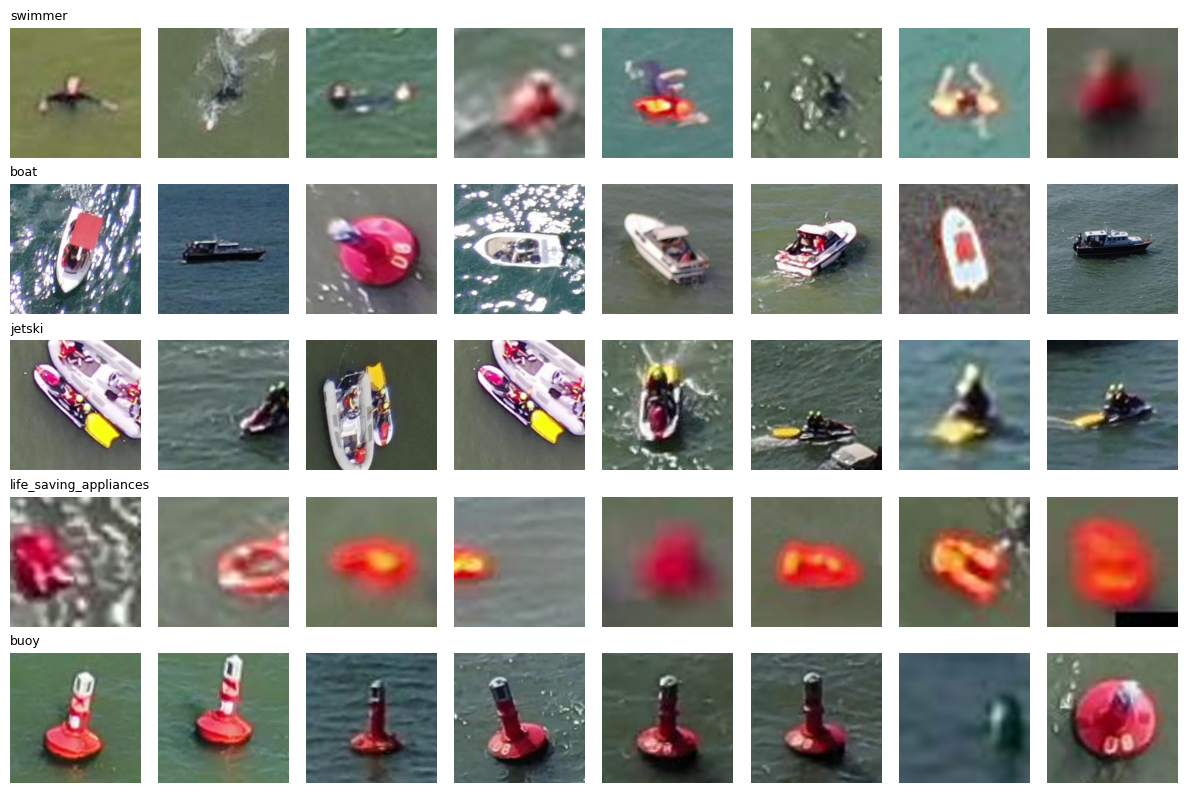

In [10]:
# Show a few crops per class to check that the cropping is correct
cls_ids = sorted(KEEP_CATS)
fig, axes = plt.subplots(len(cls_ids), 8, figsize=(12, 1.6 * len(cls_ids)))
for r, cid in enumerate(cls_ids):
    idx = np.where(G_lab == cid)[0][:8]
    for c in range(8):
        ax = axes[r, c]; ax.axis("off")
        if c < len(idx): ax.imshow(G_imgs[idx[c]])
    axes[r, 0].set_title(KEEP_CATS[cid], loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 7. Load the models and extract features (all frozen, no training)

**DINOv3 (torch.hub, official repo `facebookresearch/dinov3`)**
- `torch.hub.load('facebookresearch/dinov3', 'dinov3_vitb16', source='github', weights=<local .pth path>)`. `weights` can also be a URL, but we use the file in Drive to avoid downloading it every time.
- Preprocessing follows the official README (LVD-1689M weights): `Resize` → `ToDtype(float, scale=True)` → `Normalize(ImageNet mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225))`. The input side length must be a multiple of the **patch size 16**; we use 224 → 14×14 = 196 patches. (The README example uses 256 by default, but our crops are already 224, so we use 224.)
- `model.forward_features(x)` returns a dict:
  - `x_norm_clstoken`: `[B, 768]`, the **CLS token** after LayerNorm → global feature (this is also what `model(x)` returns, since the head is Identity)
  - `x_storage_tokens`: `[B, 4, 768]`, the 4 **register tokens**
  - `x_norm_patchtokens`: `[B, 196, 768]`, the **patch tokens** → averaged to give the **GAP** feature
- **DINOv2 (fallback)**: `dinov2_vitb14_reg`, same `forward_features` interface, except the register key is called `x_norm_regtokens` and the patch size is 14 (224 → 16×16 = 256 patches). The weights are public and downloaded automatically.

**CLIP (HF transformers, public model)**: the pooled output of the vision encoder goes through `visual_projection` (equivalent to `get_image_features()`), giving an embedding in the shared image–text space.

All features are **L2-normalised**, and similarity is **cosine similarity**.

In [11]:
from transformers import CLIPModel, CLIPProcessor

def l2n(x): return torch.nn.functional.normalize(x.float(), dim=-1)
n_params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6

# Transform for the LVD-1689M weights from the official README (ImageNet mean/std)
dino_tf = v2.Compose([
    v2.ToImage(),
    v2.Resize((CFG["DINO_IMG_SIZE"], CFG["DINO_IMG_SIZE"]), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])

DINO_MODELS = {}   # name -> model
if CFG["USE_DINOV3"] and DINOV3_WEIGHTS_PATH:
    m = torch.hub.load("facebookresearch/dinov3", CFG["DINOV3_ARCH"], source="github",
                       trust_repo=True, weights=DINOV3_WEIGHTS_PATH)
    DINO_MODELS["DINOv3"] = m.to(device).eval()
if CFG["USE_DINOV2"]:
    m = torch.hub.load("facebookresearch/dinov2", CFG["DINOV2_ARCH"], source="github", trust_repo=True)
    DINO_MODELS["DINOv2"] = m.to(device).eval()
for name, m in DINO_MODELS.items():
    print(f"{name}: {n_params(m):.0f}M params, patch={m.patch_size}, dim={m.embed_dim}")
if not DINO_MODELS:
    print("⚠️ No DINO model loaded (check Sections 1 and 2). Only CLIP will run below.")

clip_model = CLIPModel.from_pretrained(CFG["CLIP_ID"]).to(device).eval()
clip_proc  = CLIPProcessor.from_pretrained(CFG["CLIP_ID"])
print(f"CLIP vision: {n_params(clip_model.vision_model):.0f}M params")

@torch.inference_mode()
def extract_dino(name, model, images, bs=CFG["BATCH_SIZE"]):
    cls_feats, gap_feats = [], []
    for i in range(0, len(images), bs):
        x = torch.stack([dino_tf(im) for im in images[i:i+bs]]).to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            out = model.forward_features(x)
        cls_feats.append(l2n(out["x_norm_clstoken"]).cpu())
        gap_feats.append(l2n(out["x_norm_patchtokens"].mean(1)).cpu())
    return {f"{name}-CLS": torch.cat(cls_feats).numpy(), f"{name}-GAP": torch.cat(gap_feats).numpy()}

@torch.inference_mode()
def extract_clip(images, bs=CFG["BATCH_SIZE"]):
    feats = []
    for i in range(0, len(images), bs):
        inp = clip_proc(images=images[i:i+bs], return_tensors="pt").to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            # pooled CLS of the vision encoder → visual_projection (= get_image_features, but robust to transformers version differences)
            f = clip_model.visual_projection(clip_model.vision_model(pixel_values=inp["pixel_values"]).pooler_output)
        feats.append(l2n(f).cpu())
    return {"CLIP": torch.cat(feats).numpy()}

def extract_all(images):
    d, msg = {}, []
    for name, m in DINO_MODELS.items():
        t0 = time.time(); d.update(extract_dino(name, m, images)); msg.append(f"{name} {time.time()-t0:.1f}s")
    t0 = time.time(); d.update(extract_clip(images)); msg.append(f"CLIP {time.time()-t0:.1f}s")
    print(f"  {len(images)} imgs | " + " | ".join(msg))
    return d

print("Gallery:"); G_feat = extract_all(G_imgs)
print("Query:");   Q_feat = extract_all(Q_imgs)
for k, v in G_feat.items(): print(f"  {k}: dim={v.shape[1]}")

# DINO features used by default in the plots below: DINOv3 if available, otherwise DINOv2
MAIN_DINO = next((f"{n}-CLS" for n in ["DINOv3", "DINOv2"] if f"{n}-CLS" in G_feat), None)
print("MAIN_DINO =", MAIN_DINO)

Downloading: "https://github.com/facebookresearch/dinov3/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "file:///content/drive/MyDrive/dinov3_weights/dinov3_vitb16_pretrain_lvd1689m.pth" to /root/.cache/torch/hub/checkpoints/dinov3_vitb16_pretrain_lvd1689m.pth


100%|██████████| 327M/327M [00:10<00:00, 33.4MB/s]


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_reg4_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_reg4_pretrain.pth


100%|██████████| 330M/330M [00:00<00:00, 353MB/s]


... (10 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP vision: 86M params
Gallery:
  2000 imgs | DINOv3 12.8s | DINOv2 9.3s | CLIP 6.7s
Query:
  500 imgs | DINOv3 2.3s | DINOv2 2.4s | CLIP 1.7s
  DINOv3-CLS: dim=768
  DINOv3-GAP: dim=768
  DINOv2-CLS: dim=768
  DINOv2-GAP: dim=768
  CLIP: dim=512
MAIN_DINO = DINOv3-CLS


## 8. Retrieval metrics

For each query, the gallery is sorted by cosine similarity from high to low; every gallery item of the **same class** counts as relevant:

- **AP (Average Precision)**: precision computed at the position of each relevant result, then averaged; measures the quality of the **whole ranking**.
  **mAP** = mean AP over all queries (dominated by large classes); **macro-mAP** = average per class first, then over classes (equal weight per class, fairer under class imbalance).
  With the default settings there are exactly 100 queries per class, so mAP and macro-mAP are **identical**. This is expected.
- **Recall@K**: fraction of queries with **at least one** correct result in the top K (the common definition in retrieval).
- **Precision@K**: average fraction of correct results in the top K.

> Note: the absolute mAP value depends on the class proportions in the gallery (AP of a random ranking ≈ that class's share of the gallery), so a random baseline is also printed below.

In [12]:
def retrieval_metrics(q, g, ql, gl, ks=(1, 5, 10), exclude_self=False, ignore=None):
    # ignore: optional [Q, G] bool mask; gallery items marked True are treated as absent for that query (used to remove near-duplicates)
    sim = q @ g.T                                       # [Q, G] cosine similarity
    if exclude_self:                                    # for when query and gallery are the same set of images (leave-one-out)
        ignore = np.eye(len(q), dtype=bool) if ignore is None else (ignore | np.eye(len(q), dtype=bool))
    if ignore is not None:
        sim = np.where(ignore, -np.inf, sim)            # ignored items are ranked last
    order = np.argsort(-sim, axis=1)
    rel = gl[order] == ql[:, None]                      # [Q, G] same class or not
    if ignore is not None:
        rel &= ~np.take_along_axis(ignore, order, axis=1)
    cum = np.cumsum(rel, axis=1)
    prec_at = cum / np.arange(1, rel.shape[1] + 1)
    ap = (prec_at * rel).sum(1) / np.maximum(rel.sum(1), 1)
    res = {"mAP": ap.mean(),
           "macro-mAP": np.mean([ap[ql == c].mean() for c in np.unique(ql)])}
    for k in ks:
        res[f"R@{k}"] = rel[:, :k].any(1).mean()
    for k in ks:
        res[f"P@{k}"] = rel[:, :k].mean(1).mean()
    per_class = {c: ap[ql == c].mean() for c in np.unique(ql)}
    return res, per_class, order

import pandas as pd
rows, per_cls_rows, ORDERS = [], {}, {}
for name in G_feat:
    res, pc, order = retrieval_metrics(Q_feat[name], G_feat[name], Q_lab, G_lab)
    rows.append({"model": name, **res}); per_cls_rows[name] = {KEEP_CATS[c]: v for c, v in pc.items()}; ORDERS[name] = order

# random baseline: expected AP of a random ranking ≈ that class's share of the gallery
frac = {c: (G_lab == c).mean() for c in np.unique(G_lab)}
rows.append({"model": "random", "mAP": np.mean([frac[c] for c in Q_lab]),
             "macro-mAP": np.mean([frac[c] for c in np.unique(Q_lab)])})
results = pd.DataFrame(rows).set_index("model")
per_class = pd.DataFrame(per_cls_rows).T
display(results.style.format("{:.3f}", na_rep="-"))
display(per_class.style.format("{:.3f}").set_caption("per-class AP"))

,mAP,macro-mAP,R@1,R@5,R@10,P@1,P@5,P@10
model,,,,,,,,
DINOv3-CLS,0.684,0.684,0.974,0.996,1.000,0.974,0.960,0.948
DINOv3-GAP,0.629,0.629,0.964,0.998,0.998,0.964,0.957,0.944
DINOv2-CLS,0.661,0.661,0.958,0.996,0.998,0.958,0.933,0.925
DINOv2-GAP,0.580,0.580,0.962,0.998,0.998,0.962,0.930,0.915
CLIP,0.576,0.576,0.912,0.982,0.994,0.912,0.887,0.868
random,0.200,0.200,-,-,-,-,-,-


,swimmer,boat,jetski,life_saving_appliances,buoy
DINOv3-CLS,0.565,0.625,0.772,0.724,0.734
DINOv3-GAP,0.510,0.623,0.632,0.689,0.693
DINOv2-CLS,0.591,0.666,0.732,0.650,0.664
DINOv2-GAP,0.488,0.593,0.619,0.639,0.559
CLIP,0.409,0.545,0.641,0.708,0.580


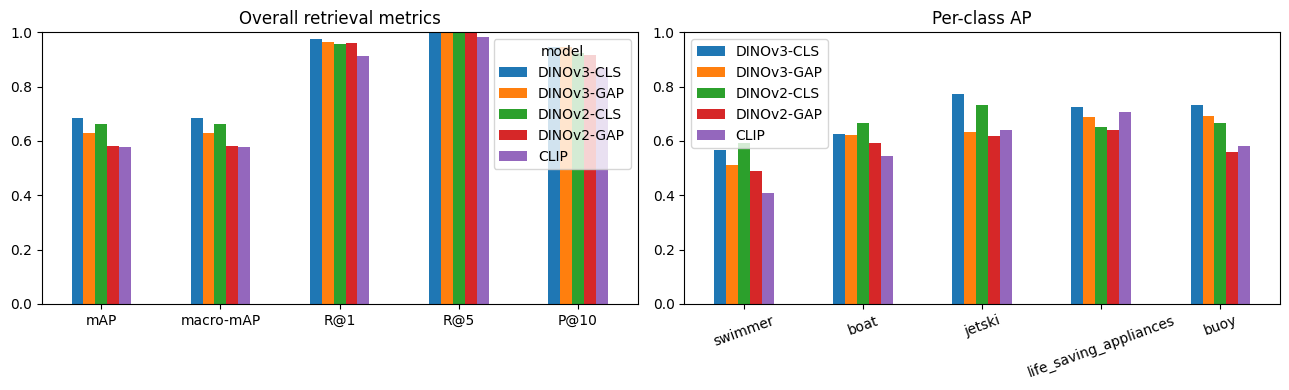

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results.drop("random")[["mAP", "macro-mAP", "R@1", "R@5", "P@10"]].T.plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Overall retrieval metrics"); axes[0].set_ylim(0, 1)
per_class.T.plot.bar(ax=axes[1], rot=20)
axes[1].set_title("Per-class AP"); axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

### 8.1 Qualitative results: what does each model retrieve for the same query?

Green border = same class (correct), red border = wrong. We pick queries where the two models **disagree**; these work best in the presentation.

DINOv3-CLS right & CLIP wrong: 32 queries;  CLIP right & DINOv3-CLS wrong: 1 queries


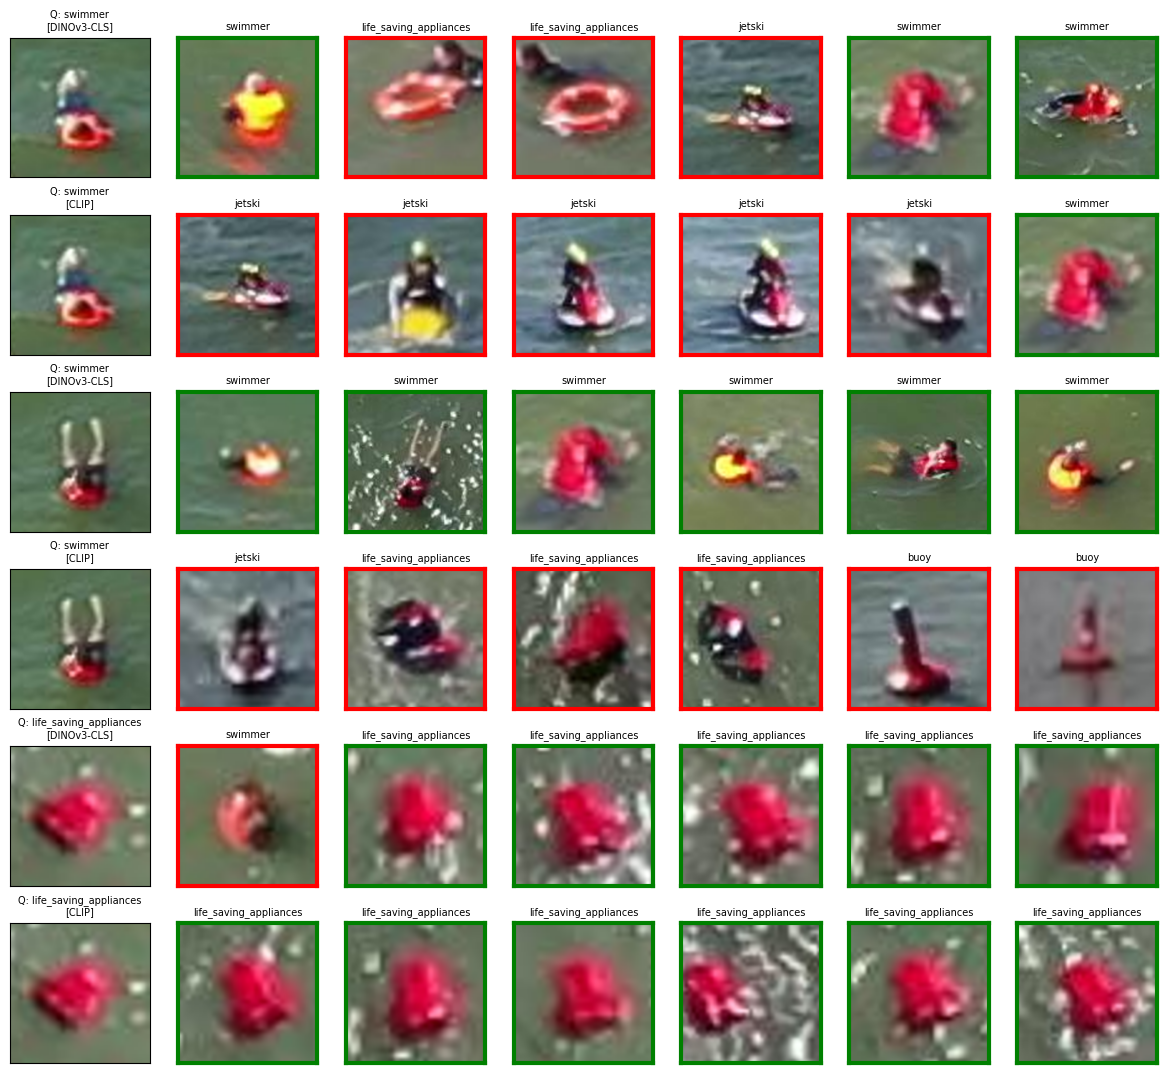

In [14]:
def show_retrievals(q_indices, models=None, topk=6):
    models = models or [m for m in (MAIN_DINO, "CLIP") if m]
    n = len(q_indices) * len(models)
    fig, axes = plt.subplots(n, topk + 1, figsize=(1.7 * (topk + 1), 1.8 * n))
    r = 0
    for qi in q_indices:
        for m in models:
            axes[r, 0].imshow(Q_imgs[qi]); axes[r, 0].set_title(f"Q: {KEEP_CATS[Q_lab[qi]]}\n[{m}]", fontsize=7)
            for k in range(topk):
                gi = ORDERS[m][qi, k]
                ax = axes[r, k + 1]; ax.imshow(G_imgs[gi])
                ok = G_lab[gi] == Q_lab[qi]
                for s in ax.spines.values(): s.set_edgecolor("green" if ok else "red"); s.set_linewidth(3)
                ax.set_title(KEEP_CATS[G_lab[gi]], fontsize=7)
            r += 1
    for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()

# Find queries where the top-1 result is correct for one model and wrong for the other
if MAIN_DINO:
    d_ok = G_lab[ORDERS[MAIN_DINO][:, 0]] == Q_lab
    c_ok = G_lab[ORDERS["CLIP"][:, 0]] == Q_lab
    dino_wins = np.where(d_ok & ~c_ok)[0]; clip_wins = np.where(~d_ok & c_ok)[0]
    print(f"{MAIN_DINO} right & CLIP wrong: {len(dino_wins)} queries;  CLIP right & {MAIN_DINO} wrong: {len(clip_wins)} queries")
    pick_q = list(dino_wins[:2]) + list(clip_wins[:2])
    if pick_q: show_retrievals(pick_q)

### 8.2 Near-duplicate / leakage check

Most SeaDronesSee images are **video frames**. If train and val come from the same video, the gallery may contain crops **almost identical** to the query (same object, neighbouring frame). R@1 then becomes very high, but it measures "finding the same object again" rather than "finding other objects of the same class".

We do two things here:
1. Print the fields of each image in the annotations / metadata to see whether there is video or folder information (if so, the cleanest approach is to split queries and gallery by video).
2. Find near-duplicates with a **model-independent** criterion: shrink crops to 32×32 pixels and compute the pixel-level Pearson correlation. For each query, gallery crops with correlation > `DUP_THRESH` are treated as "not present", and the metrics are recomputed.

The lower `DUP_THRESH`, the more crops are removed. Look at the histogram before choosing, and consider reporting results for several thresholds.

In [15]:
# 1) Look at the metadata of each image (are there video / folder / time fields?)
print("Example COCO image entry:", next(iter(tr_imgs.values())))
for p in glob.glob(os.path.join(os.path.dirname(TRAIN_JSON), "*metadata*.csv")):
    print("\\n", os.path.basename(p)); display(pd.read_csv(p).head(3))

Example COCO image entry: {'id': 3388, 'file_name': '3388.jpg', 'height': 2160, 'width': 3840, 'source': {'drone': 'mavic', 'folder_name': 'DJI_0032', 'video': 'DJI_0032.MP4', 'frame_no': 0}, 'date_time': '2020-08-25T14:16:21', 'meta': {'image_name': 'DJI_0032_merged.MP4_image0.png', 'datetime(utc)': '2020-08-25 12:16:22', 'latitude': 47.673596, 'longitude': 9.270249, 'height_above_takeoff(meter)': 9.699526973483694, 'speed(m/s)': 0.0, 'xspeed(m/s)': 0.0, 'yspeed(m/s)': 0.0, 'zspeed(m/s)': 0.0, 'compass_heading(degrees)': 175.8, 'gimbal_heading(degrees)': 154.4, 'gimbal_pitch(degrees)': -2.5}}
\n val_images_metadata.csv


,file_name,height,width,date_time,frame,drone,folder_name,video,frame_no,image_name,...,gps_latitude_ref,gps_longitude_ref,altitude,gimbal_pitch,speed,xspeed,yspeed,zspeed,gps_latitude,gps_longitude
0,3464.jpg,2160,3840,2020-08-25T14:19:21.647133,NaN,mavic,DJI_0032,DJI_0032.MP4,5415.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3465.jpg,2160,3840,2020-08-25T14:19:22.147633,NaN,mavic,DJI_0032,DJI_0032.MP4,5430.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3466.jpg,2160,3840,2020-08-25T14:19:22.648133,NaN,mavic,DJI_0032,DJI_0032.MP4,5445.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\n train_images_metadata.csv


,file_name,height,width,date_time,frame,drone,folder_name,video,frame_no,image_name,...,gps_latitude_ref,gps_longitude_ref,altitude,gimbal_pitch,speed,xspeed,yspeed,zspeed,gps_latitude,gps_longitude
0,3388.jpg,2160,3840,2020-08-25T14:16:21,NaN,mavic,DJI_0032,DJI_0032.MP4,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3389.jpg,2160,3840,2020-08-25T14:16:21.467133,NaN,mavic,DJI_0032,DJI_0032.MP4,15.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3390.jpg,2160,3840,2020-08-25T14:16:21.967633,NaN,mavic,DJI_0032,DJI_0032.MP4,30.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


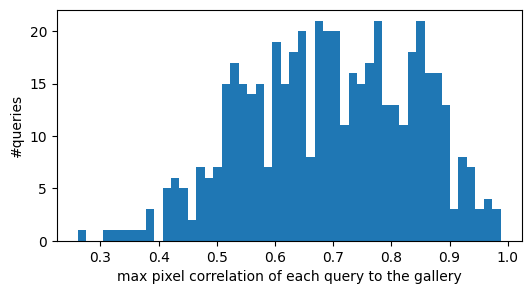

corr > 0.98: 0.4% of queries have at least one near-duplicate in the gallery; on average 0.0 per query
corr > 0.95: 1.8% of queries have at least one near-duplicate in the gallery; on average 0.0 per query
corr > 0.9: 5.6% of queries have at least one near-duplicate in the gallery; on average 0.1 per query
corr > 0.8: 27.0% of queries have at least one near-duplicate in the gallery; on average 1.3 per query
After removing near-duplicates with pixel corr > 0.9:


,mAP,macro-mAP,R@1,R@5,R@10,P@1,P@5,P@10
model,,,,,,,,
DINOv3-CLS,0.684,0.684,0.974,0.996,1.000,0.974,0.960,0.947
DINOv3-GAP,0.629,0.629,0.964,0.998,0.998,0.964,0.957,0.944
DINOv2-CLS,0.661,0.661,0.958,0.996,0.998,0.958,0.933,0.925
DINOv2-GAP,0.580,0.580,0.962,0.998,0.998,0.962,0.930,0.914
CLIP,0.576,0.576,0.912,0.982,0.994,0.912,0.886,0.868


,mAP,macro-mAP,R@1,R@5,R@10,P@1,P@5,P@10
model,,,,,,,,
DINOv3-CLS,-0.000,-0.000,+0.000,+0.000,+0.000,+0.000,+0.000,-0.000
DINOv3-GAP,-0.000,-0.000,+0.000,+0.000,+0.000,+0.000,+0.000,-0.000
DINOv2-CLS,-0.000,-0.000,+0.000,+0.000,+0.000,+0.000,-0.000,-0.001
DINOv2-GAP,-0.000,-0.000,+0.000,+0.000,+0.000,+0.000,-0.000,-0.001
CLIP,-0.000,-0.000,+0.000,+0.000,+0.000,+0.000,-0.000,-0.000


In [16]:
# 2) Model-independent near-duplicate detection: Pearson correlation on 32x32 pixels
def thumbs(imgs):
    x = np.stack([np.asarray(im.resize((32, 32), Image.BILINEAR), dtype=np.float32).ravel() for im in imgs])
    x -= x.mean(1, keepdims=True)
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-8)

PIX = thumbs(Q_imgs) @ thumbs(G_imgs).T          # [Q, G] pixel correlation
max_corr = PIX.max(1)
plt.figure(figsize=(6, 3)); plt.hist(max_corr, bins=50)
plt.xlabel("max pixel correlation of each query to the gallery"); plt.ylabel("#queries"); plt.show()
for t in [0.98, 0.95, 0.9, 0.8]:
    print(f"corr > {t}: {(max_corr > t).mean():.1%} of queries have at least one near-duplicate in the gallery; on average {(PIX > t).sum(1).mean():.1f} per query")

DUP_THRESH = 0.9   # adjust based on the histogram above
IGNORE = PIX > DUP_THRESH
rows_d = []
for name in G_feat:
    res, _, _ = retrieval_metrics(Q_feat[name], G_feat[name], Q_lab, G_lab, ignore=IGNORE)
    rows_d.append({"model": name, **res})
results_dedup = pd.DataFrame(rows_d).set_index("model")
print(f"After removing near-duplicates with pixel corr > {DUP_THRESH}:")
display(results_dedup.style.format("{:.3f}"))
display((results_dedup - results.drop("random")).style.format("{:+.3f}").set_caption("Change (dedup - original)"))

## 9. Extra experiment A: CLIP text → image retrieval (DINO cannot do this)

CLIP has a text encoder, so it can retrieve images from a sentence and do zero-shot classification. DINOv3/DINOv2 only have visual features without text alignment; this is exactly how the two differ in purpose.

Here one prompt per class is used as the query to compute AP on the gallery; the same prompts are then used for zero-shot classification of the query crops. Try changing the prompts to see how the scores change (CLIP is very sensitive to prompt engineering).

In [17]:
PROMPT = "an aerial drone photo of a {} in the sea"
# Putting the raw class name into a prompt is not always natural (e.g. "life saving appliances" rarely appears in CLIP's training text),
# so each class gets a more natural description. Edit this to compare prompt-engineering variants.
CLASS_TEXT = {"swimmer": "person swimming", "boat": "boat", "jetski": "jet ski",
              "life_saving_appliances": "orange life ring or life jacket floating", "buoy": "buoy"}
cls_ids = sorted(np.unique(G_lab))
texts = [PROMPT.format(CLASS_TEXT.get(KEEP_CATS[c], KEEP_CATS[c].replace("_", " "))) for c in cls_ids]
print(texts)
with torch.inference_mode():
    tin = clip_proc(text=texts, return_tensors="pt", padding=True).to(device)
    T = l2n(clip_model.text_projection(clip_model.text_model(**tin).pooler_output)).cpu().numpy()

# text -> image retrieval
res_t, pc_t, _ = retrieval_metrics(T, G_feat["CLIP"], np.array(cls_ids), G_lab)
print("Text→Image AP per class:", {KEEP_CATS[c]: round(v, 3) for c, v in pc_t.items()})
print(f"Text→Image mAP = {res_t['mAP']:.3f}")

# zero-shot classification of query crops
pred = np.array(cls_ids)[(Q_feat["CLIP"] @ T.T).argmax(1)]
print(f"CLIP zero-shot accuracy on query crops = {(pred == Q_lab).mean():.3f}")
for c in cls_ids:
    m = Q_lab == c
    print(f"  {KEEP_CATS[c]:>25s}: {(pred[m] == c).mean():.3f}  (n={m.sum()})")

['an aerial drone photo of a person swimming in the sea', 'an aerial drone photo of a boat in the sea', 'an aerial drone photo of a jet ski in the sea', 'an aerial drone photo of a orange life ring or life jacket floating in the sea', 'an aerial drone photo of a buoy in the sea']
Text→Image AP per class: {'swimmer': np.float64(0.46), 'boat': np.float64(0.637), 'jetski': np.float64(0.565), 'life_saving_appliances': np.float64(0.225), 'buoy': np.float64(0.557)}
Text→Image mAP = 0.489
CLIP zero-shot accuracy on query crops = 0.714
                    swimmer: 0.520  (n=100)
                       boat: 0.570  (n=100)
                     jetski: 0.730  (n=100)
     life_saving_appliances: 0.890  (n=100)
                       buoy: 0.860  (n=100)


## 10. Extra experiment B: Robustness — how much does retrieval drop when the queries are perturbed?

Object orientation in aerial images is arbitrary, so **rotation** is especially interesting; **blur / low resolution** simulate small, distant objects; **grayscale** removes colour cues (e.g. life-saving equipment is often orange).
Seeing which model drops more helps discuss the "geometric/visual structure vs semantics" hypothesis, but conclusions should be based on the data.

  500 imgs | DINOv3 2.6s | DINOv2 2.6s | CLIP 1.9s
  500 imgs | DINOv3 2.5s | DINOv2 2.4s | CLIP 1.7s
  500 imgs | DINOv3 2.5s | DINOv2 2.6s | CLIP 1.9s
  500 imgs | DINOv3 2.5s | DINOv2 2.4s | CLIP 1.7s
  500 imgs | DINOv3 2.6s | DINOv2 2.8s | CLIP 1.8s


,DINOv3-CLS,DINOv3-GAP,DINOv2-CLS,DINOv2-GAP,CLIP
original,0.684,0.629,0.661,0.580,0.576
rotate90,0.589,0.547,0.560,0.501,0.508
hflip,0.684,0.629,0.662,0.578,0.578
grayscale,0.639,0.595,0.589,0.557,0.447
blur(r=2),0.688,0.632,0.662,0.581,0.487
lowres32,0.643,0.613,0.625,0.565,0.392


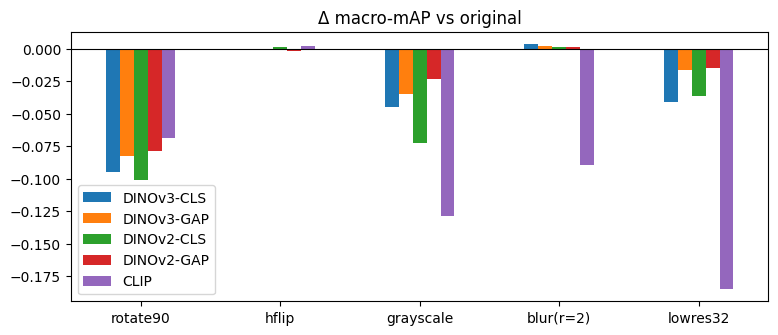

In [18]:
PERTURB = {
    "original":  lambda im: im,
    "rotate90":  lambda im: im.rotate(90),
    "hflip":     lambda im: ImageOps.mirror(im),
    "grayscale": lambda im: ImageOps.grayscale(im).convert("RGB"),
    "blur(r=2)": lambda im: im.filter(ImageFilter.GaussianBlur(2)),
    "lowres32":  lambda im: im.resize((32, 32), Image.BILINEAR).resize((224, 224), Image.BILINEAR),
}
rob = {}
for pname, fn in PERTURB.items():
    feats = Q_feat if pname == "original" else extract_all([fn(im) for im in Q_imgs])
    rob[pname] = {m: retrieval_metrics(feats[m], G_feat[m], Q_lab, G_lab)[0]["macro-mAP"] for m in G_feat}
rob = pd.DataFrame(rob).T
display(rob.style.format("{:.3f}").set_caption("macro-mAP under query perturbations"))
(rob - rob.loc["original"]).drop("original").plot.bar(rot=0, figsize=(9, 3.5), title="Δ macro-mAP vs original")
plt.axhline(0, color="k", lw=0.8); plt.show()

## 11. Extra experiment C: t-SNE visualisation of the feature space

Project the gallery features to 2D to see whether same-class items cluster together. This is a very intuitive figure for the presentation (note that t-SNE only shows local structure; distances between clusters have no strict meaning).

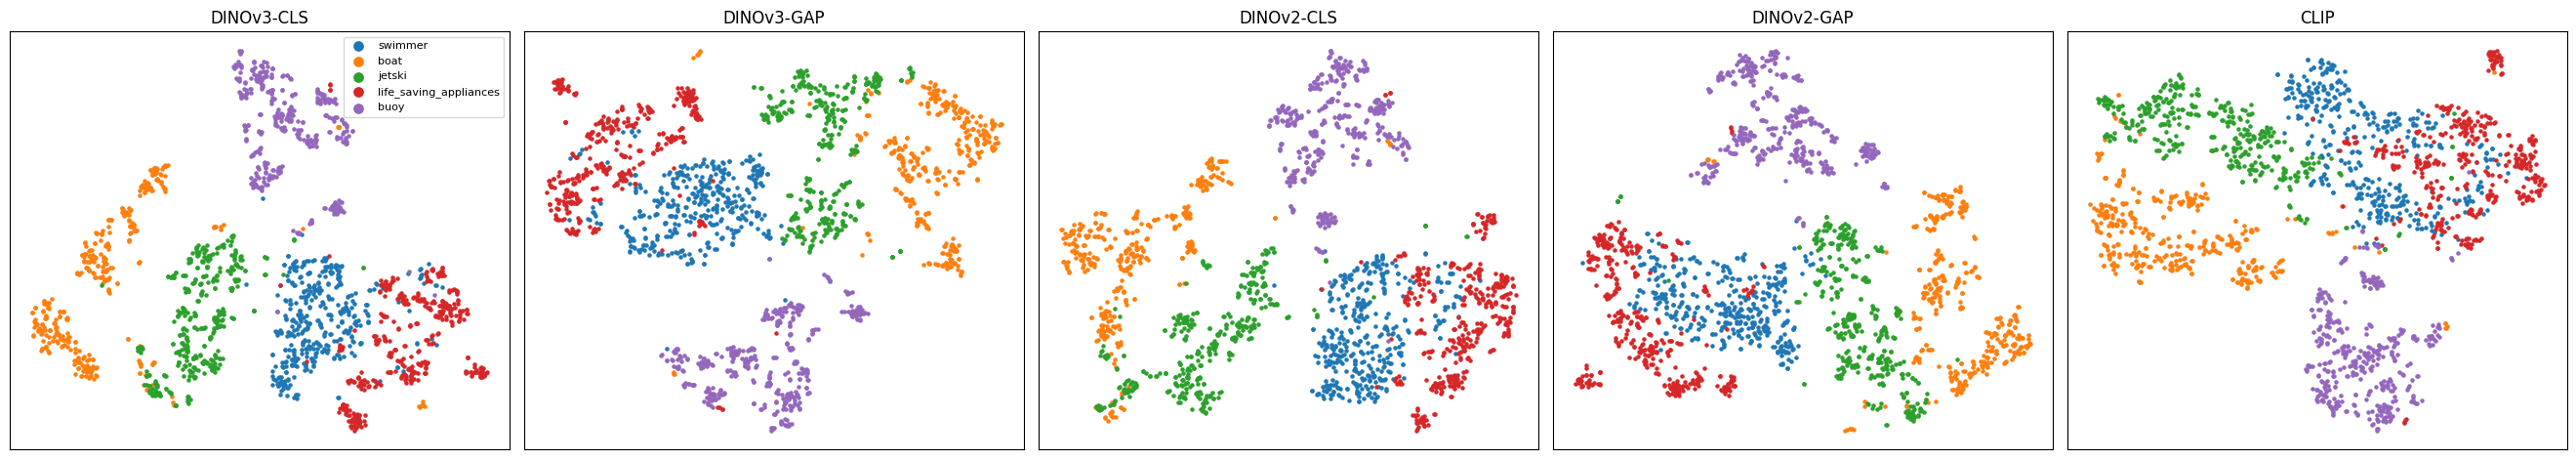

In [19]:
from sklearn.manifold import TSNE
tsne_models = list(G_feat)
fig, axes = plt.subplots(1, len(tsne_models), figsize=(5.3 * len(tsne_models), 4.8), squeeze=False)
axes = axes[0]
for ax, m in zip(axes, tsne_models):
    emb = TSNE(n_components=2, init="pca", perplexity=30, random_state=0).fit_transform(G_feat[m])
    for c in cls_ids:
        k = G_lab == c
        ax.scatter(emb[k, 0], emb[k, 1], s=5, label=KEEP_CATS[c])
    ax.set_title(m); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()

## 12. (Optional) Sanity check: retrieval on CIFAR-10

First confirm that the pipeline works on a standard, clean dataset (both models should get a high mAP). Set `CFG["RUN_SANITY_CIFAR"] = True` and run.
This uses 100 test images per class with **leave-one-out** (each image is a query and the rest form the gallery). CIFAR images are only 32×32 and are upscaled to 224, so this is only a sanity check.

In [20]:
if CFG["RUN_SANITY_CIFAR"]:
    import torchvision
    ds = torchvision.datasets.CIFAR10("/content/cifar", train=False, download=True)
    per = defaultdict(list)
    for i, y in enumerate(ds.targets):
        if len(per[y]) < 100: per[y].append(i)
    idx = [i for y in sorted(per) for i in per[y]]
    c_imgs = [ds[i][0].resize((224, 224), Image.BICUBIC) for i in idx]
    c_lab = np.array([ds.targets[i] for i in idx])
    c_feat = extract_all(c_imgs)
    display(pd.DataFrame({m: retrieval_metrics(f, f, c_lab, c_lab, exclude_self=True)[0] for m, f in c_feat.items()}).T.style.format("{:.3f}"))
else:
    print("Skipped (RUN_SANITY_CIFAR=False)")

Skipped (RUN_SANITY_CIFAR=False)


## 13. Save results & clean up

- Result tables and features are saved to `/content/results/` (Colab's temporary disk). To keep them, you can mount **Google Drive** (also in the cloud, not on your computer). The feature files are only a few MB, not the 10 GB dataset.
- Colab's disk is wiped when the runtime disconnects, so the dataset disappears automatically. To free space immediately, run the last line.

In [21]:
os.makedirs("/content/results", exist_ok=True)
results.to_csv("/content/results/retrieval_metrics.csv")
per_class.to_csv("/content/results/per_class_ap.csv")
rob.to_csv("/content/results/robustness.csv")
results_dedup.to_csv("/content/results/retrieval_metrics_dedup.csv")
np.savez_compressed("/content/results/features.npz", G_lab=G_lab, Q_lab=Q_lab,
                    **{f"G_{k}": v for k, v in G_feat.items()}, **{f"Q_{k}": v for k, v in Q_feat.items()})
print(os.listdir("/content/results"))

SAVE_TO_DRIVE = False
if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    !mkdir -p /content/drive/MyDrive/1MD049_task1 && cp -r /content/results/* /content/drive/MyDrive/1MD049_task1/

['retrieval_metrics.csv', 'retrieval_metrics_dedup.csv', 'robustness.csv', 'per_class_ap.csv', 'features.npz']


In [22]:
# Optional: delete the downloaded dataset now to free Colab disk (not needed, and not possible, for a read-only /kaggle/input mount)
# !rm -rf ~/.cache/kagglehub /content/sds_extracted

## 14. Discussion points for the presentation (not conclusions)

After running, the discussion can be organised around these questions:
1. Which model has the higher mAP / macro-mAP? Which classes does the gap mainly come from (the small classes jetski and life_saving_appliances are often hardest)?
2. Which is better for DINO, **CLS or GAP**? What does this say about the global semantic token vs local patch features?
3. Which model is more stable under **rotation / blur / low-res**? Is this consistent with the claim that "DINOv3 leans towards visual structure, CLIP towards semantics"?
4. How well does CLIP do on text→image and zero-shot? This is an ability DINOv3 lacks; what is the cost?
5. Limitations: class imbalance, extremely small objects, near-duplicates from video frames (leakage), only class-level relevance (no instance-level).

6. If both DINOv2 and DINOv3 were run: where does DINOv3 improve over DINOv2? (Note the different patch sizes: 14 vs 16.)

Possible extensions: larger backbones (`dinov3_vitl16` vs `clip-vit-large-patch14`, requires the matching weight URL from the email), tuning `PAD_RATIO` to see the effect of context, and trying patch-level matching beyond CLS.